In [3]:
import pandas as pd

raw = pd.read_excel("data/fbil_2026-10-16.xlsx", header=None)
print(raw.shape)
raw.head(40) 

(129, 8)


,0,1,2,3,4,5,6,7
0,NaN,Financial Benchmarks India Private Ltd,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,FBIL GSec Prices/Yields,NaN,16-Oct-2026,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ISIN,Coupon,Maturity(dd-mmm-yyyy),Price(Rs),YTM% p.a. (Semi-Annual),Remark 1,Remark 2,NaN
5,IN0020230119,7.33,2026-10-30 00:00:00,100.0349,6.0637,NaN,NaN,NaN
6,IN0020210186,5.74,2026-11-15 00:00:00,100.0198,5.3945,NaN,NaN,NaN
7,IN0020140060,8.15,2026-11-24 00:00:00,100.2456,5.4918,NaN,NaN,NaN
8,IN0020060078,8.24,2027-02-15 00:00:00,100.6649,6.08,NaN,NaN,NaN
9,IN0020170026,6.79,2027-05-15 00:00:00,100.1292,6.544,NaN,NaN,NaN


In [4]:
path = "data/fbil_2026-10-16.xlsx"
print(pd.ExcelFile(path).sheet_names)
raw = pd.read_excel(path, header=None)
raw.tail(60)

['G-Sec', 'Par Yield', 'Special', 'Note on FRB & IIB']


,0,1,2,3,4,5,6,7
69,IN0020240126,6.79,2034-10-07 00:00:00,96.9497,7.3011,Input Point,NaN,Proxy
70,IN0020240159,6.79,2034-12-02 00:00:00,96.8259,7.3135,NaN,NaN,NaN
71,IN0020150051,7.73,2034-12-19 00:00:00,102.5862,7.3015,NaN,NaN,NaN
72,IN0020200245,6.22,2035-03-16 00:00:00,93.2933,7.3,NaN,NaN,NaN
73,IN0020250026,6.33,2035-05-05 00:00:00,94.0406,7.2782,Input Point,NaN,Proxy
74,IN0020210020,6.64,2035-06-16 00:00:00,95.5496,7.3416,NaN,NaN,NaN
75,IN0020050012,7.4,2035-09-09 00:00:00,100.3552,7.3431,NaN,YC,NaN
76,IN0020250091,6.48,2035-10-06 00:00:00,94.4002,7.3431,Input Point,NaN,T
77,IN0020210152,6.67,2035-12-15 00:00:00,95.4326,7.3626,NaN,NaN,NaN
78,IN0020260025,6.94,2036-05-11 00:00:00,97.0628,7.3725,Input Point,NaN,T


124 bonds
           isin  coupon   maturity     price     ytm     years
5  IN0020230119    7.33 2026-10-30  100.0349  6.0637  0.038330
6  IN0020210186    5.74 2026-11-15  100.0198  5.3945  0.082136
7  IN0020140060    8.15 2026-11-24  100.2456  5.4918  0.106776
8  IN0020060078    8.24 2027-02-15  100.6649  6.0800  0.334018
9  IN0020170026    6.79 2027-05-15  100.1292  6.5440  0.577687


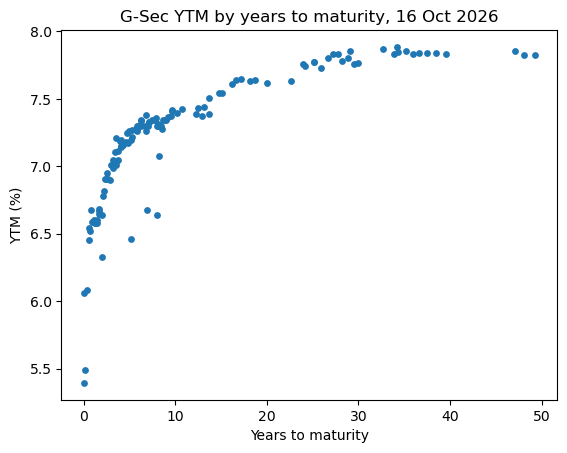

In [5]:
import matplotlib.pyplot as plt

val_date = pd.to_datetime(raw.iloc[2, 2], format="%d-%b-%Y")

hdr = raw.index[raw[0] == "ISIN"][0]
df = raw.iloc[hdr + 1:, :5].copy()
df.columns = ["isin", "coupon", "maturity", "price", "ytm"]
df = df[df["isin"].astype(str).str.startswith("IN")]

df["maturity"] = pd.to_datetime(df["maturity"], errors="coerce")
for col in ["coupon", "price", "ytm"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna()

df["years"] = (df["maturity"] - val_date).dt.days / 365.25
print(len(df), "bonds")
print(df.head())

plt.scatter(df["years"], df["ytm"], s=15)
plt.title("G-Sec YTM by years to maturity, 16 Oct 2026")
plt.xlabel("Years to maturity")
plt.ylabel("YTM (%)")
plt.show()

In [6]:
def load_fbil(path):
    raw = pd.read_excel(path, header=None)
    val_date = pd.to_datetime(raw.iloc[2, 2], format="%d-%b-%Y")
    hdr = raw.index[raw[0] == "ISIN"][0]
    df = raw.iloc[hdr + 1:, :8].copy()
    df.columns = ["isin", "coupon", "maturity", "price", "ytm", "remark1", "remark2", "remark3"]
    df = df[df["isin"].astype(str).str.startswith("IN")]
    df["maturity"] = pd.to_datetime(df["maturity"], errors="coerce")
    for col in ["coupon", "price", "ytm"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["maturity", "price", "ytm"])
    df["years"] = (df["maturity"] - val_date).dt.days / 365.25
    return val_date, df

d16, df16 = load_fbil("data/fbil_2026-10-16.xlsx")
print(d16.date(), len(df16), "bonds")

2026-10-16 124 bonds


In [7]:
df16[df16["years"].between(1, 12)].sort_values("ytm").head(12)

,isin,coupon,maturity,price,ytm,remark1,remark2,remark3,years
124,IN0020210160,6.45,2028-10-04,100.6000,6.3287,FRB,GOI FRB 2028,T,1.968515
125,IN0020180041,6.64,2031-12-07,102.6475,6.4600,FRB,GOI FRB 2031,NaN,5.141684
15,IN0020170174,7.17,2028-01-08,100.6696,6.5772,NaN,YC,NaN,1.229295
16,IN0020220136,7.10,2028-01-27,100.6140,6.5772,NaN,YC,NaN,1.281314
18,IN0020230010,7.06,2028-04-10,100.6656,6.5772,Input Point,NaN,Proxy,1.483915
17,IN0020020247,6.01,2028-03-25,99.1996,6.6003,NaN,NaN,NaN,1.440110
14,IN0020240167,6.64,2027-12-09,100.0266,6.6053,NaN,NaN,NaN,1.147159
127,IN0020210137,6.45,2034-10-30,102.6225,6.6400,FRB,GOI FRB 2034,NaN,8.038330
22,IN0020230101,7.37,2028-10-23,101.3514,6.6404,NaN,NaN,NaN,2.020534
20,IN0020030022,6.13,2028-06-04,99.2045,6.6483,NaN,NaN,NaN,1.634497


In [8]:
raw = pd.read_excel("data/fbil_2026-10-16.xlsx", header=None)
raw.tail(40)

,0,1,2,3,4,5,6,7
89,IN0020260041,7.06,2041-07-27 00:00:00,95.7563,7.5394,Input Point,NaN,T
90,IN0020110063,8.83,2041-12-12 00:00:00,111.5216,7.5394,NaN,YC,NaN
91,IN0020120062,8.3,2042-12-31 00:00:00,106.3704,7.6073,NaN,NaN,NaN
92,IN0020190040,7.69,2043-06-17 00:00:00,100.467,7.6383,NaN,NaN,NaN
93,IN0020130079,9.23,2043-12-23 00:00:00,114.9489,7.6497,NaN,NaN,NaN
94,IN0020140078,8.17,2044-12-01 00:00:00,105.1904,7.635,Input Point,NaN,T
95,IN0020150044,8.13,2045-06-22 00:00:00,104.8371,7.6378,NaN,NaN,NaN
96,IN0020160068,7.06,2046-10-10 00:00:00,94.3507,7.6146,NaN,NaN,NaN
97,IN0020190032,7.72,2049-06-15 00:00:00,100.9563,7.6292,NaN,NaN,NaN
98,IN0020200054,7.16,2050-09-20 00:00:00,93.4979,7.7612,NaN,NaN,NaN


In [9]:
print(df16["remark1"].value_counts(dropna=False))
print(df16["remark2"].value_counts(dropna=False).head(15))

remark1
NaN            91
Input Point    28
FRB             5
Name: count, dtype: int64
remark2
NaN             113
YC                7
GOI FRB 2028      1
GOI FRB 2031      1
GOI FRB 2033      1
GOI FRB 2034      1
Name: count, dtype: int64


124 -> 119 bonds


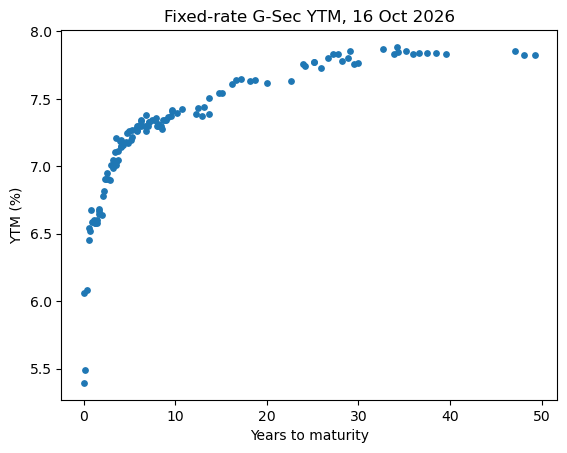

In [10]:
fixed16 = df16[~df16["remark1"].isin(["FRB", "IIB"])]
print(len(df16), "->", len(fixed16), "bonds")

plt.scatter(fixed16["years"], fixed16["ytm"], s=15)
plt.title("Fixed-rate G-Sec YTM, 16 Oct 2026")
plt.xlabel("Years to maturity")
plt.ylabel("YTM (%)")
plt.show()

In [11]:
def load_fbil(path):
    raw = pd.read_excel(path, header=None)
    val_date = pd.to_datetime(raw.iloc[2, 2], format="%d-%b-%Y")
    hdr = raw.index[raw[0] == "ISIN"][0]
    df = raw.iloc[hdr + 1:, :8].copy()
    df.columns = ["isin", "coupon", "maturity", "price", "ytm", "remark1", "remark2", "remark3"]
    df = df[df["isin"].astype(str).str.startswith("IN")]
    df["maturity"] = pd.to_datetime(df["maturity"], errors="coerce")
    for col in ["coupon", "price", "ytm"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["maturity", "price", "ytm"])
    df = df[~df["remark1"].isin(["FRB", "IIB"])]
    df["years"] = (df["maturity"] - val_date).dt.days / 365.25
    return val_date, df

In [12]:
import glob

for f in sorted(glob.glob("data/*.xlsx")):
    d, x = load_fbil(f)
    print(f, "->", d.date(), len(x), "fixed-rate bonds")

data\fbil_2026-09-09.xlsx -> 2026-09-09 119 fixed-rate bonds
data\fbil_2026-10-09.xlsx -> 2026-10-09 119 fixed-rate bonds
data\fbil_2026-10-16.xlsx -> 2026-10-16 119 fixed-rate bonds


In [13]:
for f in sorted(glob.glob("data/*.xlsx")):
    d, x = load_fbil(f)
    near10 = x.iloc[(x["years"] - 10).abs().argsort()[:1]]
    print(d.date(), "| bond nearest 10 years:", near10["isin"].values[0],
          "| years:", round(near10["years"].values[0], 2),
          "| YTM:", near10["ytm"].values[0])

2026-09-09 | bond nearest 10 years: IN0020060045 | years: 9.74 | YTM: 6.9793
2026-10-09 | bond nearest 10 years: IN0020220102 | years: 10.2 | YTM: 7.3823
2026-10-16 | bond nearest 10 years: IN0020220102 | years: 10.18 | YTM: 7.3953
